<a href="https://colab.research.google.com/github/ChristZ-coderFs/ITC3154-Customer-Churn/blob/manthos-mlp/Model_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Standard MLP vs. Residual MLP — Final Model Comparison

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json

from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve, roc_auc_score

print("Libraries imported successfully!")

Libraries imported successfully!


### Load Experimental Results

In [2]:
# Load Standard MLP results
standard_baseline = pd.read_csv("standard_mlp_baseline.csv")
standard_tuning = pd.read_csv("standard_mlp_tuning.csv")
standard_grid = pd.read_csv("standard_mlp_grid_search.csv")
standard_test = pd.read_csv("standard_mlp_test_metrics.csv")
standard_average = pd.read_csv("standard_mlp_average_metrics.csv")

# Load Residual MLP results
residual_tuning = pd.read_csv("residual_all_36_runs.csv")
residual_predictions = pd.read_csv("residual_test_predictions.csv")

with open("residual_mlp_results.json", "r") as file:
    residual_results = json.load(file)

# Verify loaded results
print("Standard MLP baseline runs:", len(standard_baseline))
print("Standard MLP tuning runs:", len(standard_tuning))
print("Standard MLP configurations:", len(standard_grid))
print("Standard MLP test evaluations:", len(standard_test))

print("\nResidual MLP tuning runs:", len(residual_tuning))
print("Residual MLP test predictions:", len(residual_predictions))

print("\nAll experimental results loaded successfully!")

Standard MLP baseline runs: 3
Standard MLP tuning runs: 36
Standard MLP configurations: 12
Standard MLP test evaluations: 6

Residual MLP tuning runs: 36
Residual MLP test predictions: 1057

All experimental results loaded successfully!


### Verify Experimental Consistency

In [3]:
# Extract shared experimental settings
standard_settings = {
    "Training Seeds": sorted(standard_tuning["Seed"].unique().tolist()),
    "Learning Rates": sorted(standard_tuning["Learning Rate"].unique().tolist()),
    "Batch Sizes": sorted(standard_tuning["Batch Size"].unique().tolist()),
    "Total Experiments": len(standard_tuning),
    "Baseline Learning Rate": standard_baseline["Learning Rate"].iloc[0],
    "Baseline Batch Size": standard_baseline["Batch Size"].iloc[0]
}

residual_settings = {
    "Training Seeds": sorted(residual_results["initial"]["seeds"]),
    "Learning Rates": sorted(residual_tuning["lr"].unique().tolist()),
    "Batch Sizes": sorted(residual_tuning["batch_size"].unique().tolist()),
    "Total Experiments": len(residual_tuning),
    "Baseline Learning Rate": residual_results["initial"]["lr"],
    "Baseline Batch Size": residual_results["initial"]["batch_size"]
}

# Compare settings
settings_comparison = pd.DataFrame([
    {
        "Setting": setting,
        "Standard MLP": standard_settings[setting],
        "Residual MLP": residual_settings[setting],
        "Match": standard_settings[setting] == residual_settings[setting]
    }
    for setting in standard_settings
])

display(settings_comparison)

print("\nAll checked settings match:",
      settings_comparison["Match"].all())

,Setting,Standard MLP,Residual MLP,Match
0,Training Seeds,"[42, 123, 456]","[42, 123, 456]",True
1,Learning Rates,"[0.0001, 0.0005, 0.001, 0.005]","[0.0001, 0.0005, 0.001, 0.005]",True
2,Batch Sizes,"[32, 64, 128]","[32, 64, 128]",True
3,Total Experiments,36,36,True
4,Baseline Learning Rate,0.001,0.001,True
5,Baseline Batch Size,64,64,True



All checked settings match: True


### Model Architecture and Complexity Comparison



,Model,Input Features,Architecture,Skip Connections,Output Neurons,Trainable Parameters
0,Standard MLP,45,64 and 32 hidden neurons,No,1,5057
1,Residual MLP,45,64 neurons with 2 residual blocks,Yes,1,19649


Parameter difference: 14592
Residual MLP is 3.89 times larger.


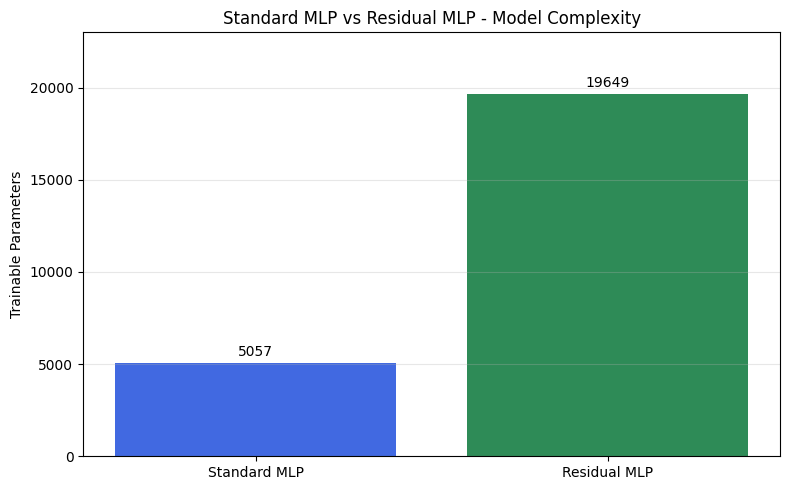

In [4]:
# Compare the architecture of both models
architecture_comparison = pd.DataFrame({
    "Model": ["Standard MLP", "Residual MLP"],
    "Input Features": [45, 45],
    "Architecture": [
        "64 and 32 hidden neurons",
        "64 neurons with 2 residual blocks"
    ],
    "Skip Connections": ["No", "Yes"],
    "Output Neurons": [1, 1],
    "Trainable Parameters": [
        5057,
        residual_results["initial"]["trainable_params"]
    ]
})

display(architecture_comparison)

# Calculate the difference in model complexity
standard_params = architecture_comparison.loc[0, "Trainable Parameters"]
residual_params = architecture_comparison.loc[1, "Trainable Parameters"]

print(f"Parameter difference: {residual_params - standard_params}")
print(f"Residual MLP is {residual_params / standard_params:.2f} times larger.")

# Visualize model complexity
plt.figure(figsize=(8, 5))

bars = plt.bar(
    architecture_comparison["Model"],
    architecture_comparison["Trainable Parameters"],
    color=["royalblue", "seagreen"]
)

plt.bar_label(bars, padding=3)
plt.ylabel("Trainable Parameters")
plt.title("Standard MLP vs Residual MLP - Model Complexity")
plt.ylim(0, 23000)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("model_complexity_comparison.png", dpi=300)
plt.show()

###  Baseline and Tuned Hyperparameter Comparison

In [5]:
# Identify the best Standard MLP configuration
standard_best = standard_grid.loc[
    standard_grid["Mean_Validation_Loss"].idxmin()
]

# Compare baseline and tuned hyperparameters
hyperparameter_comparison = pd.DataFrame({
    "Model": ["Standard MLP", "Residual MLP"],
    "Baseline Learning Rate": [
        standard_baseline["Learning Rate"].iloc[0],
        residual_results["initial"]["lr"]
    ],
    "Tuned Learning Rate": [
        standard_best["Learning Rate"],
        residual_results["tuned"]["lr"]
    ],
    "Baseline Batch Size": [
        int(standard_baseline["Batch Size"].iloc[0]),
        residual_results["initial"]["batch_size"]
    ],
    "Tuned Batch Size": [
        int(standard_best["Batch Size"]),
        residual_results["tuned"]["batch_size"]
    ]
})

display(hyperparameter_comparison)

,Model,Baseline Learning Rate,Tuned Learning Rate,Baseline Batch Size,Tuned Batch Size
0,Standard MLP,0.001,0.0005,64,64
1,Residual MLP,0.001,0.0050,64,64


### Baseline and Tuned Validation Loss Comparison

,Model,Baseline Loss,Tuned Loss,Improvement (%)
0,Standard MLP,0.417844,0.417223,0.148613
1,Residual MLP,0.420790,0.418165,0.623826


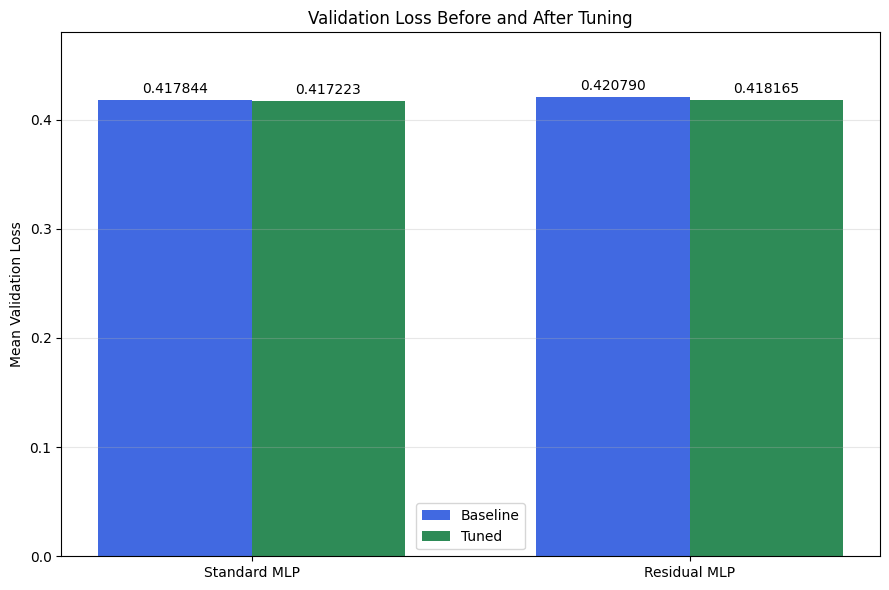

In [6]:
# Standard MLP mean validation losses
standard_initial_loss = standard_baseline["Best Validation Loss"].mean()
standard_tuned_loss = standard_best["Mean_Validation_Loss"]

# Residual MLP mean validation losses
residual_initial_loss = np.mean([
    run["val_loss"]
    for run in residual_results["initial"]["per_seed"]
])

residual_tuned_loss = np.mean([
    run["val_loss"]
    for run in residual_results["tuned"]["per_seed"]
])

# Create comparison table
validation_comparison = pd.DataFrame({
    "Model": ["Standard MLP", "Residual MLP"],
    "Baseline Loss": [
        standard_initial_loss,
        residual_initial_loss
    ],
    "Tuned Loss": [
        standard_tuned_loss,
        residual_tuned_loss
    ]
})

# Calculate percentage improvement
validation_comparison["Improvement (%)"] = (
    (validation_comparison["Baseline Loss"] -
     validation_comparison["Tuned Loss"]) /
    validation_comparison["Baseline Loss"] * 100
)

display(validation_comparison.round(6))

# Visualize validation losses
x = np.arange(len(validation_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 6))

bars1 = ax.bar(
    x - width / 2,
    validation_comparison["Baseline Loss"],
    width,
    label="Baseline",
    color="royalblue"
)

bars2 = ax.bar(
    x + width / 2,
    validation_comparison["Tuned Loss"],
    width,
    label="Tuned",
    color="seagreen"
)

ax.bar_label(bars1, fmt="%.6f", padding=3)
ax.bar_label(bars2, fmt="%.6f", padding=3)

ax.set_xticks(x)
ax.set_xticklabels(validation_comparison["Model"])
ax.set_ylabel("Mean Validation Loss")
ax.set_title("Validation Loss Before and After Tuning")
ax.set_ylim(0, 0.48)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("validation_loss_comparison.png", dpi=300)
plt.show()

###  Final Test Performance Comparison

In [7]:
# Define the evaluation metrics
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

# Calculate Standard MLP average test metrics
standard_test_summary = standard_test.groupby(
    "Configuration"
)[metrics].mean()

# Extract Residual MLP average test metrics
residual_test_summary = pd.DataFrame({
    "Accuracy": [
        residual_results["initial"]["test_accuracy_mean"],
        residual_results["tuned"]["test_accuracy_mean"]
    ],
    "Precision": [
        residual_results["initial"]["test_precision_mean"],
        residual_results["tuned"]["test_precision_mean"]
    ],
    "Recall": [
        residual_results["initial"]["test_recall_mean"],
        residual_results["tuned"]["test_recall_mean"]
    ],
    "F1 Score": [
        residual_results["initial"]["test_f1_mean"],
        residual_results["tuned"]["test_f1_mean"]
    ],
    "ROC-AUC": [
        residual_results["initial"]["test_roc_auc_mean"],
        residual_results["tuned"]["test_roc_auc_mean"]
    ]
}, index=["Baseline", "Tuned"])

# Combine both models into one comparison table
test_comparison = pd.concat(
    [standard_test_summary, residual_test_summary],
    keys=["Standard MLP", "Residual MLP"],
    names=["Model", "Configuration"]
)

# Display results and highlight the best metric values
display(
    test_comparison.style
    .format("{:.4f}")
    .highlight_max(axis=0, color="lightgreen")
)

# Identify the best configuration for each metric
print("Best configuration for each metric:\n")

for metric in metrics:
    best_model, best_config = test_comparison[metric].idxmax()
    best_value = test_comparison[metric].max()

    print(f"{metric}: {best_model} ({best_config}) - {best_value:.4f}")

Best configuration for each metric:

Accuracy: Standard MLP (Baseline) - 0.8035
Precision: Residual MLP (Tuned) - 0.6908
Recall: Standard MLP (Baseline) - 0.4769
F1 Score: Standard MLP (Baseline) - 0.5633
ROC-AUC: Standard MLP (Tuned) - 0.8454


### Test Performance Visualization

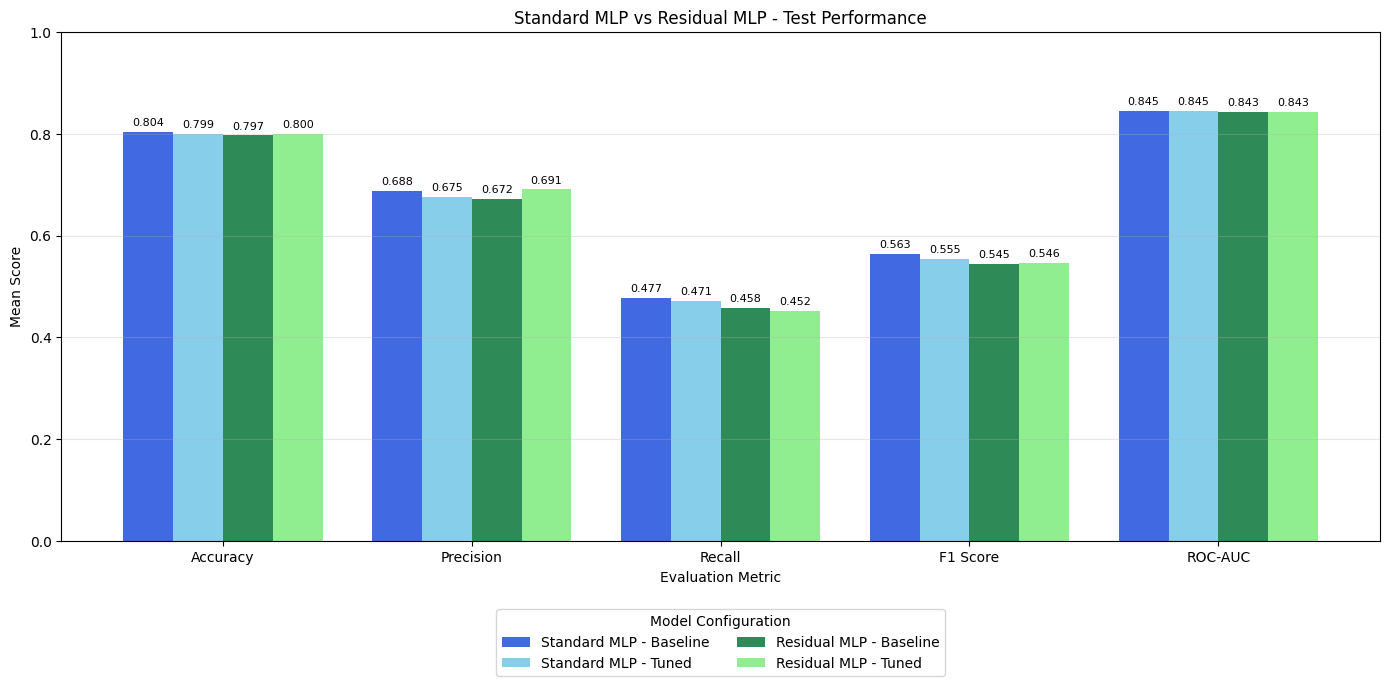

In [8]:
# Prepare results for visualization
plot_data = test_comparison.copy()

plot_data.index = [
    f"{model} - {configuration}"
    for model, configuration in plot_data.index
]

# Create grouped bar chart
ax = plot_data.T.plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8,
    color=["royalblue", "skyblue", "seagreen", "lightgreen"]
)

# Display values above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=8)

ax.set_title("Standard MLP vs Residual MLP - Test Performance")
ax.set_xlabel("Evaluation Metric")
ax.set_ylabel("Mean Score")
ax.set_ylim(0, 1)
ax.set_xticklabels(metrics, rotation=0)
ax.legend(title="Model Configuration", loc="upper center",
          bbox_to_anchor=(0.5, -0.12), ncol=2)

ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("test_performance_comparison.png", dpi=300)
plt.show()

### Majority-Class Baseline Comparison

Majority-Class Baseline Accuracy: 0.7342


,Configuration,Accuracy,Improvement (Percentage Points)
0,Standard MLP - Baseline,0.8035,6.9379
1,Standard MLP - Tuned,0.7991,6.4964
2,Residual MLP - Baseline,0.7966,6.2413
3,Residual MLP - Tuned,0.8004,6.6247


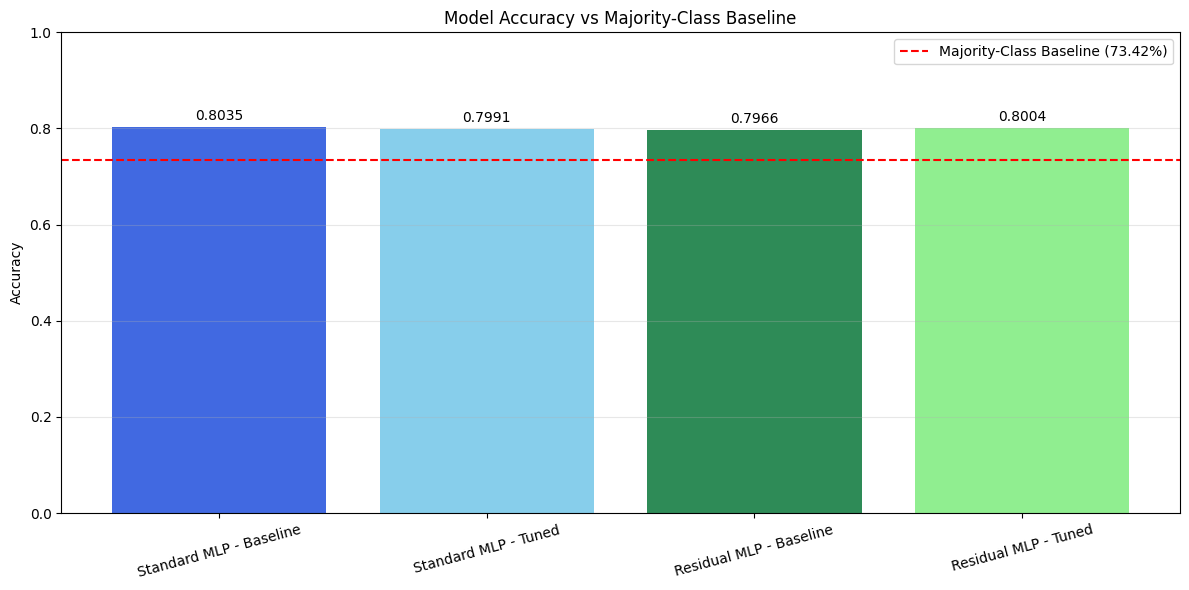

In [9]:
# Calculate majority-class baseline accuracy
majority_accuracy = (
    residual_predictions["y_true"]
    .value_counts(normalize=True)
    .max()
)

# Prepare accuracy comparison
majority_comparison = test_comparison[["Accuracy"]].reset_index()

majority_comparison["Configuration"] = (
    majority_comparison["Model"] + " - " +
    majority_comparison["Configuration"]
)

# Calculate improvement over the majority-class baseline
majority_comparison["Improvement (Percentage Points)"] = (
    majority_comparison["Accuracy"] - majority_accuracy
) * 100

print(f"Majority-Class Baseline Accuracy: {majority_accuracy:.4f}")

display(
    majority_comparison[
        ["Configuration", "Accuracy", "Improvement (Percentage Points)"]
    ].round(4)
)

# Visualize accuracy comparison
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    majority_comparison["Configuration"],
    majority_comparison["Accuracy"],
    color=["royalblue", "skyblue", "seagreen", "lightgreen"]
)

ax.axhline(
    y=majority_accuracy,
    color="red",
    linestyle="--",
    label=f"Majority-Class Baseline ({majority_accuracy:.2%})"
)

ax.bar_label(bars, fmt="%.4f", padding=3)
ax.set_title("Model Accuracy vs Majority-Class Baseline")
ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("majority_baseline_comparison.png", dpi=300)
plt.show()

### Performance Stability Across Training Seeds

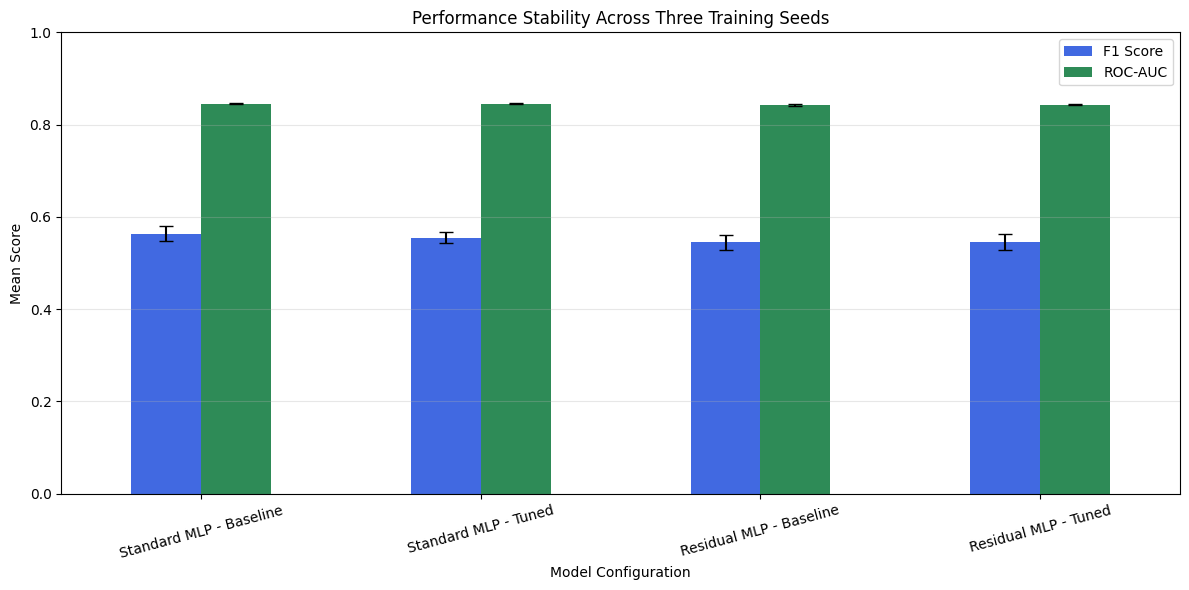

In [10]:
# Calculate Standard MLP standard deviations
standard_std = standard_test.groupby(
    "Configuration"
)[metrics].std()

# Extract Residual MLP standard deviations
residual_std = pd.DataFrame({
    "Accuracy": [
        residual_results["initial"]["test_accuracy_std"],
        residual_results["tuned"]["test_accuracy_std"]
    ],
    "Precision": [
        residual_results["initial"]["test_precision_std"],
        residual_results["tuned"]["test_precision_std"]
    ],
    "Recall": [
        residual_results["initial"]["test_recall_std"],
        residual_results["tuned"]["test_recall_std"]
    ],
    "F1 Score": [
        residual_results["initial"]["test_f1_std"],
        residual_results["tuned"]["test_f1_std"]
    ],
    "ROC-AUC": [
        residual_results["initial"]["test_roc_auc_std"],
        residual_results["tuned"]["test_roc_auc_std"]
    ]
}, index=["Baseline", "Tuned"])

# Combine standard deviations
stability_comparison = pd.concat(
    [standard_std, residual_std],
    keys=["Standard MLP", "Residual MLP"],
    names=["Model", "Configuration"]
)

# Display standard deviations
display(
    stability_comparison.style
    .format("{:.4f}")
    .highlight_min(axis=0, color="lightgreen")
)

# Prepare mean scores and standard deviations
means = test_comparison[["F1 Score", "ROC-AUC"]].copy()

errors = stability_comparison.loc[
    means.index, ["F1 Score", "ROC-AUC"]
].copy()

labels = [
    f"{model} - {configuration}"
    for model, configuration in means.index
]

means.index = labels
errors.index = labels

# Visualize performance with error bars
ax = means.plot(
    kind="bar",
    yerr=errors,
    capsize=5,
    figsize=(12, 6),
    color=["royalblue", "seagreen"]
)

ax.set_title("Performance Stability Across Three Training Seeds")
ax.set_ylabel("Mean Score")
ax.set_xlabel("Model Configuration")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("performance_stability_comparison.png", dpi=300)
plt.show()

###  Training Time and Convergence Comparison

,Configuration,Mean Training Time (s),Mean Best Epoch
0,Standard - Baseline,2.5321,8.6667
1,Standard - Tuned,3.2715,18.3333
2,Residual - Baseline,2.6629,5.3333
3,Residual - Tuned,2.7214,4.3333


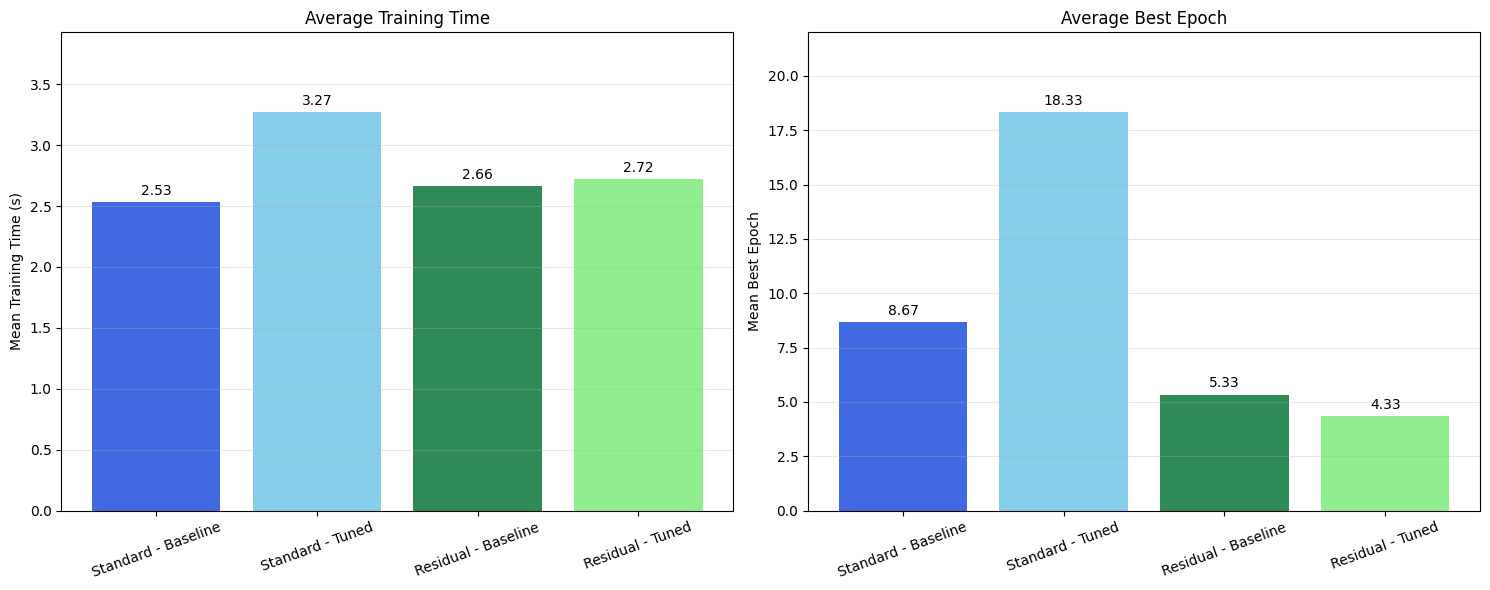

In [11]:
# Extract Standard MLP tuned runs
standard_tuned_runs = standard_tuning[
    (standard_tuning["Learning Rate"] == standard_best["Learning Rate"]) &
    (standard_tuning["Batch Size"] == standard_best["Batch Size"])
]

# Compare training times and best epochs
training_comparison = pd.DataFrame({
    "Configuration": [
        "Standard - Baseline",
        "Standard - Tuned",
        "Residual - Baseline",
        "Residual - Tuned"
    ],
    "Mean Training Time (s)": [
        standard_baseline["Training Time (s)"].mean(),
        standard_tuned_runs["Training Time (s)"].mean(),
        residual_results["initial"]["train_time_mean_sec"],
        residual_results["tuned"]["train_time_mean_sec"]
    ],
    "Mean Best Epoch": [
        standard_baseline["Best Epoch"].mean(),
        standard_tuned_runs["Best Epoch"].mean(),
        residual_results["initial"]["best_epoch_mean"],
        residual_results["tuned"]["best_epoch_mean"]
    ]
})

display(training_comparison.round(4))

# Visualize training times and best epochs
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

colors = ["royalblue", "skyblue", "seagreen", "lightgreen"]

for ax, column, title in zip(
    axes,
    ["Mean Training Time (s)", "Mean Best Epoch"],
    ["Average Training Time", "Average Best Epoch"]
):
    bars = ax.bar(
        training_comparison["Configuration"],
        training_comparison[column],
        color=colors
    )

    ax.bar_label(bars, fmt="%.2f", padding=3)
    ax.set_title(title)
    ax.set_ylabel(column)
    ax.set_ylim(0, training_comparison[column].max() * 1.2)
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("training_efficiency_comparison.png", dpi=300)
plt.show()

### Confusion Matrix Comparison

Test labels and ordering match successfully!


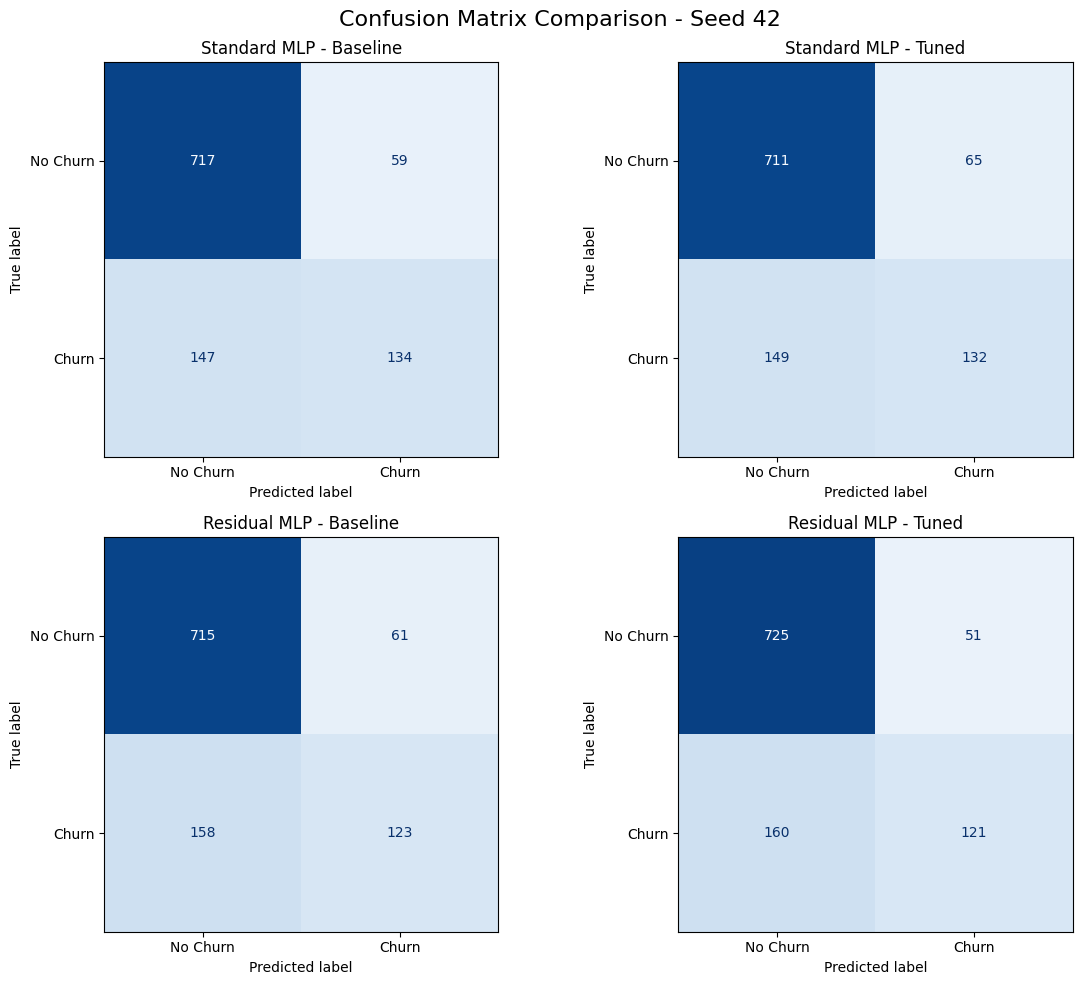

In [12]:
# Import confusion matrix visualization
from sklearn.metrics import ConfusionMatrixDisplay

# Load Standard MLP predictions for seed 42
standard_baseline_pred = pd.read_csv(
    "standard_mlp_baseline_seed_42_predictions.csv"
)

standard_tuned_pred = pd.read_csv(
    "standard_mlp_tuned_seed_42_predictions.csv"
)

# Verify that both models have matching test labels
assert np.array_equal(
    standard_baseline_pred["Actual"],
    residual_predictions["y_true"]
), "Baseline test labels do not match!"

assert np.array_equal(
    standard_tuned_pred["Actual"],
    residual_predictions["y_true"]
), "Tuned test labels do not match!"

print("Test labels and ordering match successfully!")

# Calculate confusion matrices
confusion_matrices = {
    "Standard MLP - Baseline": confusion_matrix(
        standard_baseline_pred["Actual"],
        standard_baseline_pred["Predicted"],
        labels=[0, 1]
    ),
    "Standard MLP - Tuned": confusion_matrix(
        standard_tuned_pred["Actual"],
        standard_tuned_pred["Predicted"],
        labels=[0, 1]
    ),
    "Residual MLP - Baseline": confusion_matrix(
        residual_predictions["y_true"],
        residual_predictions["initial_pred_seed42"],
        labels=[0, 1]
    ),
    "Residual MLP - Tuned": confusion_matrix(
        residual_predictions["y_true"],
        residual_predictions["tuned_pred_seed42"],
        labels=[0, 1]
    )
}

# Visualize all four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, matrix) in zip(
    axes.flatten(), confusion_matrices.items()
):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["No Churn", "Churn"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 776}
    )

    ax.set_title(name)

plt.suptitle("Confusion Matrix Comparison - Seed 42", fontsize=16)
plt.tight_layout()
plt.savefig("confusion_matrix_comparison.png", dpi=300)
plt.show()

### ROC Curve Comparison

Standard MLP - Baseline: ROC-AUC = 0.8453
Standard MLP - Tuned: ROC-AUC = 0.8461
Residual MLP - Baseline: ROC-AUC = 0.8439
Residual MLP - Tuned: ROC-AUC = 0.8418


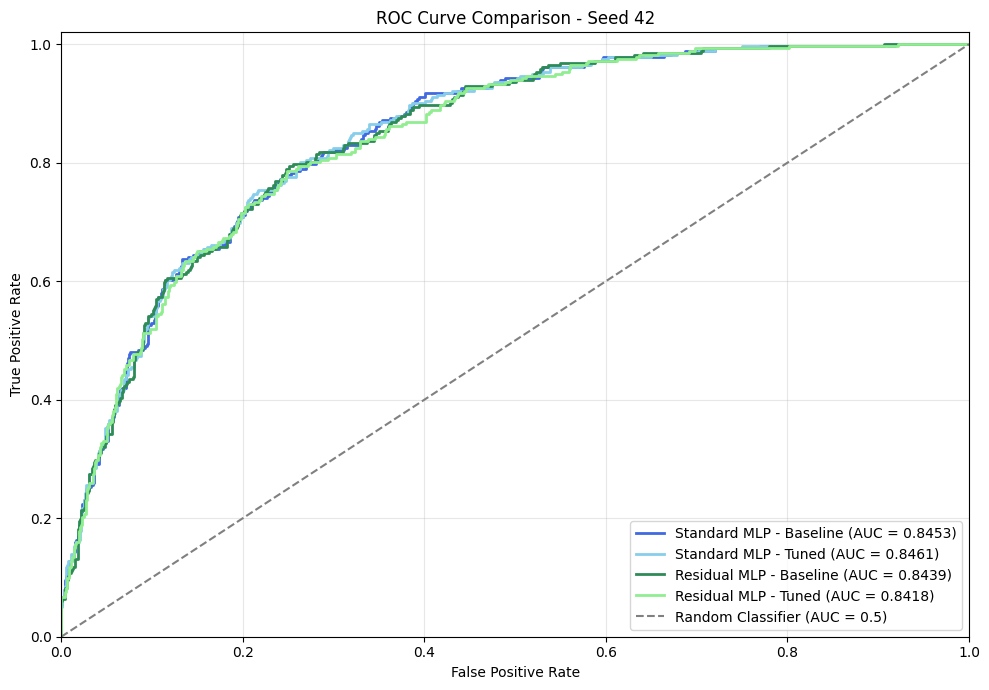

In [13]:
# Prepare probability predictions for seed 42
roc_predictions = {
    "Standard MLP - Baseline": (
        standard_baseline_pred["Actual"],
        standard_baseline_pred["Probability"]
    ),
    "Standard MLP - Tuned": (
        standard_tuned_pred["Actual"],
        standard_tuned_pred["Probability"]
    ),
    "Residual MLP - Baseline": (
        residual_predictions["y_true"],
        residual_predictions["initial_prob_seed42"]
    ),
    "Residual MLP - Tuned": (
        residual_predictions["y_true"],
        residual_predictions["tuned_prob_seed42"]
    )
}

# Define colors for each configuration
colors = ["royalblue", "skyblue", "seagreen", "lightgreen"]

# Create ROC curve comparison
plt.figure(figsize=(10, 7))

for (name, (actual, probability)), color in zip(
    roc_predictions.items(), colors
):
    fpr, tpr, thresholds = roc_curve(actual, probability)
    auc_score = roc_auc_score(actual, probability)

    plt.plot(
        fpr,
        tpr,
        color=color,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

    print(f"{name}: ROC-AUC = {auc_score:.4f}")

# Add random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier (AUC = 0.5)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Seed 42")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("roc_curve_comparison.png", dpi=300)
plt.show()

###  Classification Error Analysis

,Configuration,False Positives,False Negatives,Total Errors,Correct Predictions
0,Standard MLP - Baseline,59,147,206,851
1,Standard MLP - Tuned,65,149,214,843
2,Residual MLP - Baseline,61,158,219,838
3,Residual MLP - Tuned,51,160,211,846


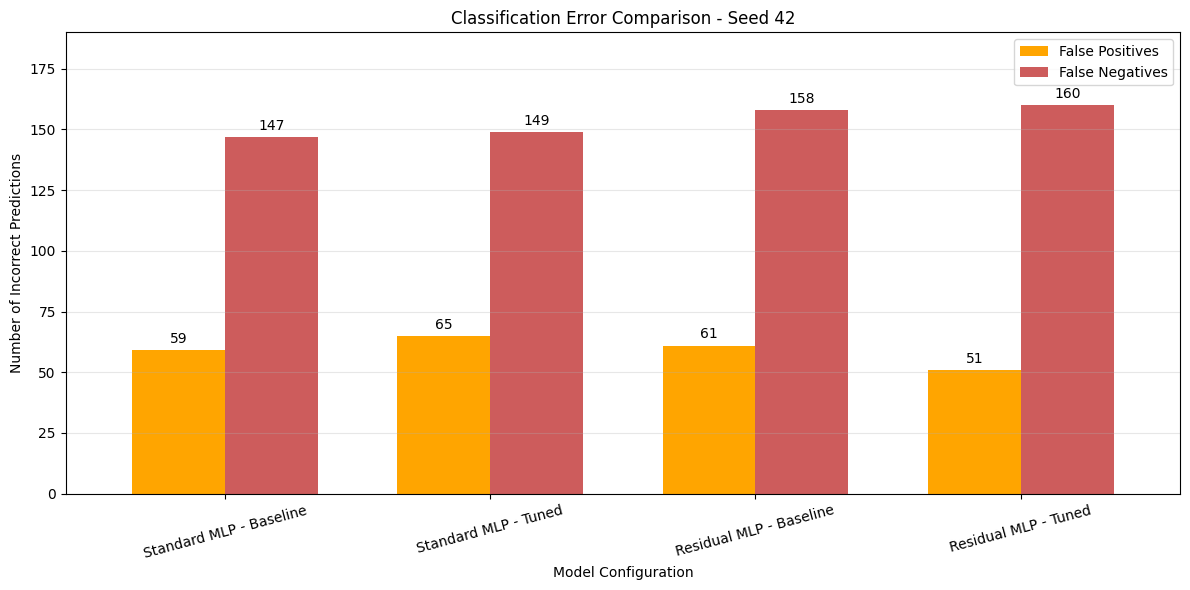

In [14]:
# Extract classification errors from confusion matrices
error_results = []

for name, matrix in confusion_matrices.items():
    tn, fp, fn, tp = matrix.ravel()

    error_results.append({
        "Configuration": name,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Errors": fp + fn,
        "Correct Predictions": tn + tp
    })

error_comparison = pd.DataFrame(error_results)

display(error_comparison)

# Visualize classification errors
ax = error_comparison.set_index("Configuration")[
    ["False Positives", "False Negatives"]
].plot(
    kind="bar",
    figsize=(12, 6),
    color=["orange", "indianred"],
    width=0.7
)

for container in ax.containers:
    ax.bar_label(container, padding=3)

ax.set_title("Classification Error Comparison - Seed 42")
ax.set_ylabel("Number of Incorrect Predictions")
ax.set_xlabel("Model Configuration")
ax.set_ylim(0, 190)
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("classification_error_comparison.png", dpi=300)
plt.show()

###  Hyperparameter Grid Search Comparison

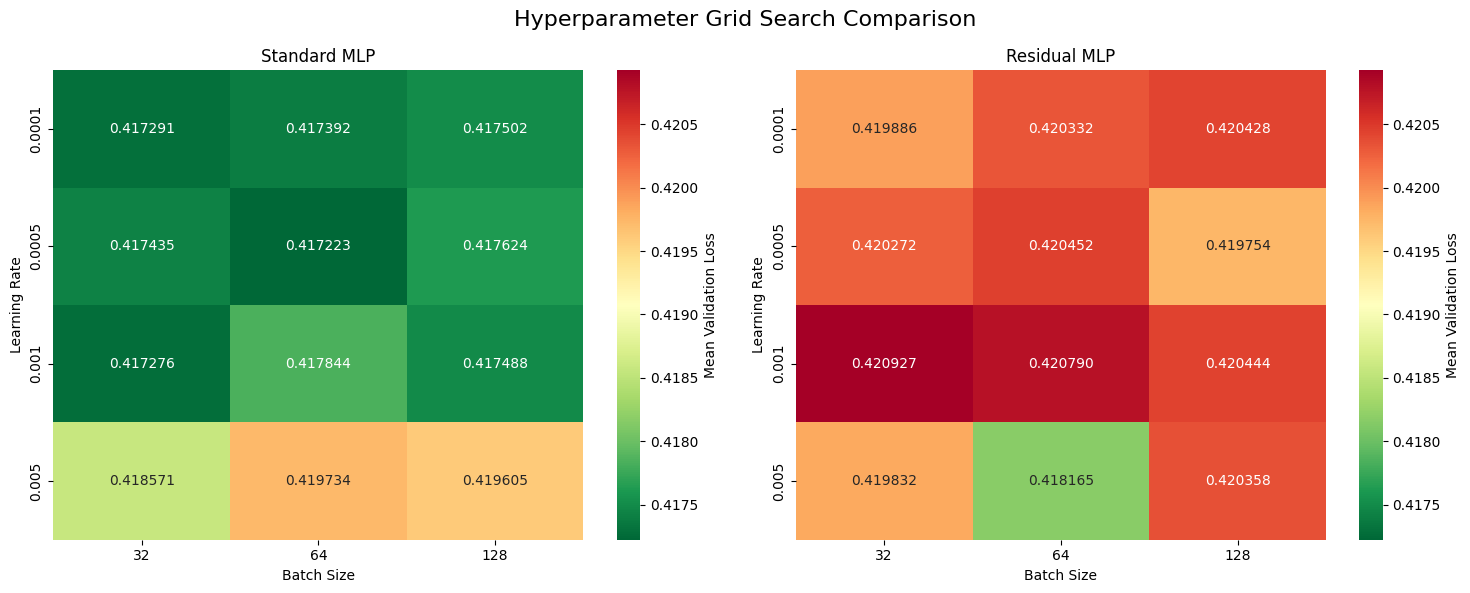

In [15]:
import seaborn as sns

# Prepare Standard MLP grid search results
standard_heatmap = standard_grid.pivot(
    index="Learning Rate",
    columns="Batch Size",
    values="Mean_Validation_Loss"
)

# Calculate Residual MLP mean validation loss
residual_grid = residual_tuning.groupby(
    ["lr", "batch_size"]
)["val_loss"].mean().reset_index()

residual_heatmap = residual_grid.pivot(
    index="lr",
    columns="batch_size",
    values="val_loss"
)

# Establish a shared color scale for fair comparison
vmin = min(
    standard_heatmap.min().min(),
    residual_heatmap.min().min()
)

vmax = max(
    standard_heatmap.max().max(),
    residual_heatmap.max().max()
)

# Visualize both grid searches
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, data, name in zip(
    axes,
    [standard_heatmap, residual_heatmap],
    ["Standard MLP", "Residual MLP"]
):
    sns.heatmap(
        data,
        annot=True,
        fmt=".6f",
        cmap="RdYlGn_r",
        vmin=vmin,
        vmax=vmax,
        ax=ax,
        cbar_kws={"label": "Mean Validation Loss"}
    )

    ax.set_title(name)
    ax.set_xlabel("Batch Size")
    ax.set_ylabel("Learning Rate")

plt.suptitle("Hyperparameter Grid Search Comparison", fontsize=16)
plt.tight_layout()
plt.savefig("grid_search_comparison.png", dpi=300)
plt.show()

### Export Final Comparison Results

In [16]:
import os
import shutil
import glob

# Create output folder
output_folder = "model_comparison_results"
os.makedirs(output_folder, exist_ok=True)

# Export comparison tables
settings_comparison.to_csv(
    f"{output_folder}/experimental_settings.csv", index=False
)

architecture_comparison.to_csv(
    f"{output_folder}/architecture_comparison.csv", index=False
)

hyperparameter_comparison.to_csv(
    f"{output_folder}/hyperparameter_comparison.csv", index=False
)

validation_comparison.to_csv(
    f"{output_folder}/validation_loss_comparison.csv", index=False
)

test_comparison.to_csv(
    f"{output_folder}/test_performance_comparison.csv"
)

majority_comparison.to_csv(
    f"{output_folder}/majority_baseline_comparison.csv", index=False
)

stability_comparison.to_csv(
    f"{output_folder}/performance_stability_comparison.csv"
)

training_comparison.to_csv(
    f"{output_folder}/training_comparison.csv", index=False
)

error_comparison.to_csv(
    f"{output_folder}/classification_error_comparison.csv", index=False
)

standard_heatmap.to_csv(
    f"{output_folder}/standard_grid_search.csv"
)

residual_heatmap.to_csv(
    f"{output_folder}/residual_grid_search.csv"
)

# Copy generated comparison graphs
for graph in glob.glob("*comparison.png"):
    shutil.copy2(graph, output_folder)

# Display exported files
print("Exported files:\n")

for filename in sorted(os.listdir(output_folder)):
    print(filename)

# Create ZIP archive
shutil.make_archive(
    "model_comparison_results",
    "zip",
    output_folder
)

print("\nAll comparison results exported successfully!")
print("ZIP file created: model_comparison_results.zip")

Exported files:

architecture_comparison.csv
classification_error_comparison.csv
classification_error_comparison.png
confusion_matrix_comparison.png
experimental_settings.csv
grid_search_comparison.png
hyperparameter_comparison.csv
majority_baseline_comparison.csv
majority_baseline_comparison.png
model_complexity_comparison.png
performance_stability_comparison.csv
performance_stability_comparison.png
residual_grid_search.csv
roc_curve_comparison.png
standard_grid_search.csv
test_performance_comparison.csv
test_performance_comparison.png
training_comparison.csv
training_efficiency_comparison.png
validation_loss_comparison.csv
validation_loss_comparison.png

All comparison results exported successfully!
ZIP file created: model_comparison_results.zip


###  Final Conclusions and Limitations

#### Key Findings

- Both architectures outperformed the majority-class baseline
  accuracy of 73.42%.
- The baseline Standard MLP achieved the highest average
  accuracy, recall and F1-score.
- The tuned Standard MLP achieved the highest average ROC-AUC.
- The tuned Residual MLP achieved the highest average precision.
- Hyperparameter tuning reduced validation loss for both
  architectures but did not improve every test metric.
- The Residual MLP contained approximately 3.89 times more
  trainable parameters than the Standard MLP.

#### Final Conclusion

The Standard MLP demonstrated comparable or slightly better
overall classification performance while requiring considerably
fewer trainable parameters.

The additional complexity of the Residual MLP did not provide
a clear overall performance advantage for this dataset.
Therefore, the Standard MLP represents a reasonable choice
when balancing model complexity and predictive performance.

#### Limitations

- Only three training seeds were used.
- The dataset contains imbalanced classes.
- Both models used a fixed classification threshold of 0.5.
- Training times may be affected by different computing
  environments.
- Confusion matrix and ROC curve comparisons were based
  on seed 42.
- The small performance differences do not establish
  statistical superiority.
- Hyperparameter tuning was limited to the selected grid.